In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from sqlalchemy import create_engine
import itertools
from matplotlib.ticker import MaxNLocator

In [3]:
engine = create_engine("mysql+pymysql://root@localhost:3306/climate_watch")

df_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCity", con=engine, parse_dates=["dt"])
df_country = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCountry", con=engine, parse_dates=["dt"])
df_major_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByMajorCity", con=engine, parse_dates=["dt"])
df_state = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByState", con=engine, parse_dates=["dt"])
df_global = pd.read_sql("SELECT * FROM GlobalTemperatures", con=engine, parse_dates=["dt"])

# Clean global data

Only 12 values are missing from the LandAverageTemperature. <br>
These are replaced by the average of the same month in 5 previous and 5 next years, and the previous and next month of the samen year.

In [3]:
# global data has 12 missing datapoints for the LandAverageTemperature
# These will be replaced by the average of the previous and next 5 years in the same month, and the previous and next month of the same year.
# The other columns are only missing for 1750-1849. There is nothing I can do about that.

df_global_sorted = df_global.sort_values("dt")
all_date_shifts = [-60, -48, -36, -24, -12, -1, 1, 12, 24, 36, 48, 60]

# Calculate replacement temperatures
df_global_sorted["LandAverageTemperatureCleaned"] = pd.DataFrame([
    df_global_sorted["LandAverageTemperature"].shift(shift) 
    for shift in all_date_shifts
]).mean(axis=0, skipna=True)
df_global_sorted["LandAverageTemperatureNew"] = df_global_sorted["LandAverageTemperature"].fillna(df_global_sorted["LandAverageTemperatureCleaned"])

# Calculate replacement temperature uncertainty
df_global_sorted["LandAverageTemperatureUncertaintyCleaned"] = pd.DataFrame([
    df_global_sorted["LandAverageTemperatureUncertainty"].shift(shift) 
    for shift in all_date_shifts
]).mean(axis=0, skipna=True)
df_global_sorted["LandAverageTemperatureUncertaintyNew"] = df_global_sorted["LandAverageTemperatureUncertainty"].fillna(df_global_sorted["LandAverageTemperatureUncertaintyCleaned"])

# Clean City data

There are 350k missing values. I will replace these by the average temperature of that period from neighboring countries.<br>
This only takes latitude and longitude into account. In reality, many other factors will influence temperature.<br><br>

### Results
This cleaning method only replaces 80.000 out of 350.000 missing values (while keeping acceptable results).<br>
Without expanding this method even more (with factors like distance to water, elevation, etc.), I don't think these results will be improved.<br>
So I am leaving these results as is.

In [4]:
def create_numeric_coordinates(df: pd.DataFrame) -> pd.DataFrame:
    north_condition = df["Latitude"].str.endswith("N")
    df["lat_numeric"] = np.where(
        north_condition, 
        df["Latitude"].str[:-1].astype(float), 
        df["Latitude"].str[:-1].astype(float)*-1
        )

    east_condition = df["Longitude"].str.endswith("E")
    df["long_numeric"] = np.where(
        east_condition, 
        df["Longitude"].str[:-1].astype(float), 
        df["Longitude"].str[:-1].astype(float)*-1
        )

    return df

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    """
    Calculates distance between two coordinates while taking Earth's curvature into account.
    """
    R = 6371  # Earth's radius in km

    lat1, lon1 = np.radians(lat1), np.radians(lon1)
    lat2, lon2 = np.radians(lat2), np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2)**2
    )

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

In [6]:
def clean_column_with_neighbors(
    df: pd.DataFrame, 
    col_to_clean: str, 
    new_col: str,
    exp_distance_multiplier: int, 
    max_distance: int, 
    min_nr_of_neighbors: int, 
    max_nr_of_neighbors: int
    ) -> pd.DataFrame:

    city_cols = ["City", "lat_numeric", "long_numeric"]

    # Table with city on x-axis en date on y-axis
    temperatures = df.pivot(
        index="dt",
        columns=city_cols,
        values=col_to_clean
    )

    latitudes = temperatures.columns.get_level_values(
        "lat_numeric"
    ).to_numpy(dtype=float)

    longitudes = temperatures.columns.get_level_values(
        "long_numeric"
    ).to_numpy(dtype=float)

    original_temps = temperatures.to_numpy(dtype=float)
    cleaned_temps = original_temps.copy()

    # Loop over all unique cities
    for lat_idx in range(len(latitudes)):

        # Find index of missing values
        missing_temp_idxs = np.where(np.isnan(original_temps[:, lat_idx]))[0]
        if len(missing_temp_idxs) == 0:
            continue

        # Calculate geographical distances between current city and others
        distances = haversine(
            latitudes[lat_idx],
            longitudes[lat_idx],
            latitudes,
            longitudes
        )

        # Exclude the city itself
        distances[lat_idx] = np.inf

        # Exclude cities outside the maximum distance
        distances[distances > max_distance] = np.inf

        # Sort neighbouring cities by distance
        all_neighbor_idxs = np.argsort(distances)
        all_neighbor_idxs = all_neighbor_idxs[np.isfinite(distances[all_neighbor_idxs])]

        # Loop over missing temperature idx's
        for temp_idx in missing_temp_idxs:

            # Select the closest cities with available temperatures
            valid_neighbor_idxs = all_neighbor_idxs[
                np.isfinite(original_temps[temp_idx, all_neighbor_idxs])
            ][:max_nr_of_neighbors]

            if len(valid_neighbor_idxs) < min_nr_of_neighbors:
                continue

            # Calculate inverse distance weights
            weights = 1 / np.maximum(distances[valid_neighbor_idxs], 1)**exp_distance_multiplier


            # Calculate weighted average
            cleaned_temps[temp_idx, lat_idx] = np.average(
                original_temps[temp_idx, valid_neighbor_idxs],
                weights=weights
            )

    row_indices = temperatures.index.get_indexer(df["dt"])

    city_indices = temperatures.columns.get_indexer(
        pd.MultiIndex.from_frame(df[city_cols])
    )

    df[new_col] = cleaned_temps[
        row_indices, city_indices
    ]

    # df = df.drop(columns=["Latitude", "Longitude"])
    return df

# Add numeric coordinates
df_city = create_numeric_coordinates(df_city)

# Create a cleaned dataset
df_city_cleaned = df_city.copy()
df_city_cleaned = clean_column_with_neighbors(
    df = df_city_cleaned,
    col_to_clean = "AverageTemperature",
    new_col = "AverageTemperatureCleaned",
    exp_distance_multiplier = 2, 
    max_distance = 500, 
    min_nr_of_neighbors = 2, 
    max_nr_of_neighbors = 25,
    )
df_city_cleaned = clean_column_with_neighbors(
    df = df_city_cleaned,
    col_to_clean = "AverageTemperatureUncertainty",
    new_col = "AverageTemperatureUncertaintyCleaned",
    exp_distance_multiplier = 2, 
    max_distance = 500, 
    min_nr_of_neighbors = 2, 
    max_nr_of_neighbors = 25,
    )


# Test the cleaning method
df_test_method = df_city[
    (df_city["dt"] > "1900-01-01")
    & (df_city["AverageTemperature"].notna())
    ].copy()
df_test_method["randint"] = np.random.choice(range(1, 101), size=len(df_test_method))
df_test_method["sampled_temp"] = np.where(df_test_method["randint"] <= 25, np.nan, df_test_method["AverageTemperature"])
df_test_method = clean_column_with_neighbors(
    df = df_test_method,
    col_to_clean = "sampled_temp", 
    new_col = "AverageTemperatureCleaned",
    exp_distance_multiplier = 2, 
    max_distance = 1000, 
    min_nr_of_neighbors = 2, 
    max_nr_of_neighbors = 10
    )

df_test_method = df_test_method[
    (df_test_method["sampled_temp"].isna())
    & (df_test_method["AverageTemperature"].notna())
    ]
df_test_method["error"] = abs(df_test_method["AverageTemperatureCleaned"] - df_test_method["AverageTemperature"])
display(df_test_method.error.describe())

nr_of_missing_temps = len(df_test_method)
nr_of_replaced_temps = len(df_test_method[df_test_method["AverageTemperatureCleaned"].notna()])

print(f"{nr_of_replaced_temps} out of {nr_of_missing_temps} are present.")

count    1.192324e+06
mean     3.773078e-01
std      1.125695e+00
min      0.000000e+00
25%      7.810425e-06
50%      5.945198e-05
75%      1.021071e-03
max      2.774517e+01
Name: error, dtype: float64

1192324 out of 1195599 are present.


### Test multiple parameters

In [ ]:
test_multipliers = [2, 4]
test_distances = [250, 500, 1000]
test_min_neighbors = [1, 2, 5]
test_max_neighbors = [10, 25]

all_combinations = list(itertools.product(test_multipliers, test_distances, test_min_neighbors, test_max_neighbors))

results = []
for test_idx, (multiplier, max_distance, min_neighbors, max_neighbors) in enumerate(all_combinations):
    print(f"Test {test_idx+1}/{len(all_combinations)} is being performed.")
    df_test = df_city[
        (df_city["dt"] > "1900-01-01")
        & (df_city["AverageTemperature"].notna())
        ].copy()
    df_test["randint"] = np.random.choice(range(1, 101), size=len(df_test))
    df_test["sampled_temp"] = np.where(df_test["randint"] <= 25, np.nan, df_test["AverageTemperature"])
    df_test = clean_column_with_neighbors(
        df = df_test,
        col_to_clean = "sampled_temp", 
        new_col = "AverageTemperatureCleaned"
        exp_distance_multiplier = multiplier,
        max_distance = max_distance,
        min_nr_of_neighbors = min_neighbors,
        max_nr_of_neighbors = max_neighbors
        )

    df_test = df_test[df_test["sampled_temp"].isna()]
    df_test["error"] = abs(df_test["AverageTemperatureCleaned"] - df_test["AverageTemperature"])
    description = df_test.error.describe().to_dict()
    results.append(description)

testing_results = pd.DataFrame(results)
testing_results[["multipliers", "distances", "min_neighbors", "max_neighbors"]] = np.array(all_combinations)
display(testing_results.sort_values("max"))

,count,mean,std,min,25%,50%,75%,max,parameters,multipliers,distances,min_neighbors,max_neighbors
5,914548.0,0.160282,0.700013,0.0,1.509505e-05,5.628080e-05,2.042000e-04,13.684733,"(2, 250, 5, 25)",2,250,5,25
4,914455.0,0.163372,0.711806,0.0,3.272043e-06,2.961915e-05,1.446639e-04,13.907466,"(2, 250, 5, 10)",2,250,5,10
23,914748.0,0.157971,0.697830,0.0,4.293303e-10,1.575568e-09,5.615266e-09,14.097798,"(4, 250, 5, 25)",4,250,5,25
22,915836.0,0.160448,0.699604,0.0,9.835333e-11,8.584129e-10,4.142547e-09,14.204085,"(4, 250, 5, 10)",4,250,5,10
2,1085013.0,0.257279,0.869081,0.0,5.267557e-06,3.928677e-05,2.448025e-04,16.688000,"(2, 250, 2, 10)",2,250,2,10
20,1086280.0,0.254257,0.856714,0.0,1.569411e-10,1.130695e-09,7.057914e-09,17.757000,"(4, 250, 2, 10)",4,250,2,10
3,1085072.0,0.255880,0.860584,0.0,1.720517e-05,6.619447e-05,3.363950e-04,17.887000,"(2, 250, 2, 25)",2,250,2,25
18,1142039.0,0.298246,0.928154,0.0,1.531006e-10,1.219540e-09,9.890311e-09,18.146000,"(4, 250, 1, 10)",4,250,1,10
21,1086818.0,0.252879,0.851986,0.0,4.906795e-10,1.856080e-09,9.240214e-09,18.208000,"(4, 250, 2, 25)",4,250,2,25
19,1142828.0,0.296769,0.927021,0.0,4.789555e-10,1.953458e-09,1.284881e-08,18.344000,"(4, 250, 1, 25)",4,250,1,25


In [ ]:
test_multipliers = [2]
test_distances = [50, 100, 250]
test_min_neighbors = [1, 2, 5]
test_max_neighbors = [25]

all_combinations = list(itertools.product(test_multipliers, test_distances, test_min_neighbors, test_max_neighbors))

results = []
for test_idx, (multiplier, max_distance, min_neighbors, max_neighbors) in enumerate(all_combinations):
    print(f"Test {test_idx+1}/{len(all_combinations)} is being performed.")
    df_test = df_city[
        (df_city["dt"] > "1900-01-01")
        & (df_city["AverageTemperature"].notna())
        ].copy()
    df_test["randint"] = np.random.choice(range(1, 101), size=len(df_test))
    df_test["sampled_temp"] = np.where(df_test["randint"] <= 25, np.nan, df_test["AverageTemperature"])
    df_test = clean_column_with_neighbors(
        df = df_test,
        col_to_clean = "sampled_temp", 
        new_col = "AverageTemperatureCleaned",
        exp_distance_multiplier = multiplier,
        max_distance = max_distance,
        min_nr_of_neighbors = min_neighbors,
        max_nr_of_neighbors = max_neighbors
        )

    df_test = df_test[df_test["sampled_temp"].isna()]
    df_test["error"] = abs(df_test["AverageTemperatureCleaned"] - df_test["AverageTemperature"])
    description = df_test.error.describe().to_dict()
    results.append(description)

testing_results = pd.DataFrame(results)
testing_results[["multipliers", "distances", "min_neighbors", "max_neighbors"]] = np.array(all_combinations)
testing_results.sort_values("max")

Test 1/9 is being performed.
Test 2/9 is being performed.
Test 3/9 is being performed.
Test 4/9 is being performed.
Test 5/9 is being performed.
Test 6/9 is being performed.
Test 7/9 is being performed.
Test 8/9 is being performed.
Test 9/9 is being performed.


,count,mean,std,min,25%,50%,75%,max,multipliers,distances,min_neighbors,max_neighbors
0,898651.0,4.996318e-16,1.331827e-15,0.0,0.000000,0.000000,0.000000e+00,1.421085e-14,2,50,1,25
2,361238.0,1.119329e-15,1.854641e-15,0.0,0.000000,0.000000,1.776357e-15,1.421085e-14,2,50,5,25
3,899641.0,5.009218e-16,1.337689e-15,0.0,0.000000,0.000000,0.000000e+00,1.421085e-14,2,100,1,25
4,671847.0,6.669514e-16,1.503915e-15,0.0,0.000000,0.000000,0.000000e+00,1.421085e-14,2,100,2,25
5,361067.0,1.119262e-15,1.837318e-15,0.0,0.000000,0.000000,1.776357e-15,1.421085e-14,2,100,5,25
1,672596.0,6.646675e-16,1.497204e-15,0.0,0.000000,0.000000,0.000000e+00,1.776357e-14,2,50,2,25
8,916050.0,1.611365e-01,7.041431e-01,0.0,0.000015,0.000056,2.046668e-04,1.400605e+01,2,250,5,25
6,1142951.0,2.972897e-01,9.317940e-01,0.0,0.000017,0.000070,4.568226e-04,1.809800e+01,2,250,1,25
7,1084054.0,2.558473e-01,8.617910e-01,0.0,0.000017,0.000066,3.341005e-04,1.833000e+01,2,250,2,25


De maximale afstand van 500 lijkt toch het beste. Dit geeft een mooie balans tussen aantal vervangende waardes en correctheid van de vervangende waardes.<br>
Verder is er geen duidelijk verband tussen de verschillende multipliers, dus die zet ik op 2.<br>
Het minimale aantal buren bepaald voor een gedeelte hoeveel waardes vervangen worden, en het maximum heeft vooral effect op de run time denk ik. <br>

# Clean df_major_city
The method from above will also be applied to the major city dataset.<br>
However, because there are much less cities in this dataset, the number of cities that are close enough to each other to be considered neighbors is also much less.

In [7]:
df_major_city = create_numeric_coordinates(df_major_city)

df_major_city_cleaned = df_major_city.copy()
df_major_city_cleaned = clean_column_with_neighbors(
    df = df_major_city_cleaned,
    col_to_clean = "AverageTemperature", 
    new_col = "AverageTemperatureCleaned",
    exp_distance_multiplier = 2, 
    max_distance = 500, 
    min_nr_of_neighbors = 2, 
    max_nr_of_neighbors = 25,
    )

df_major_city_cleaned = clean_column_with_neighbors(
    df = df_major_city_cleaned,
    col_to_clean = "AverageTemperatureUncertainty", 
    new_col = "AverageTemperatureUncertaintyCleaned",
    exp_distance_multiplier = 2, 
    max_distance = 500, 
    min_nr_of_neighbors = 2, 
    max_nr_of_neighbors = 25,
    )

## Investigate the origin of the missing values
I want to know:
- if the current missing values are stand alone errors, or if the errors are consecutive
- if there are many errors in a specific time period
- If there are many errors in a specific region

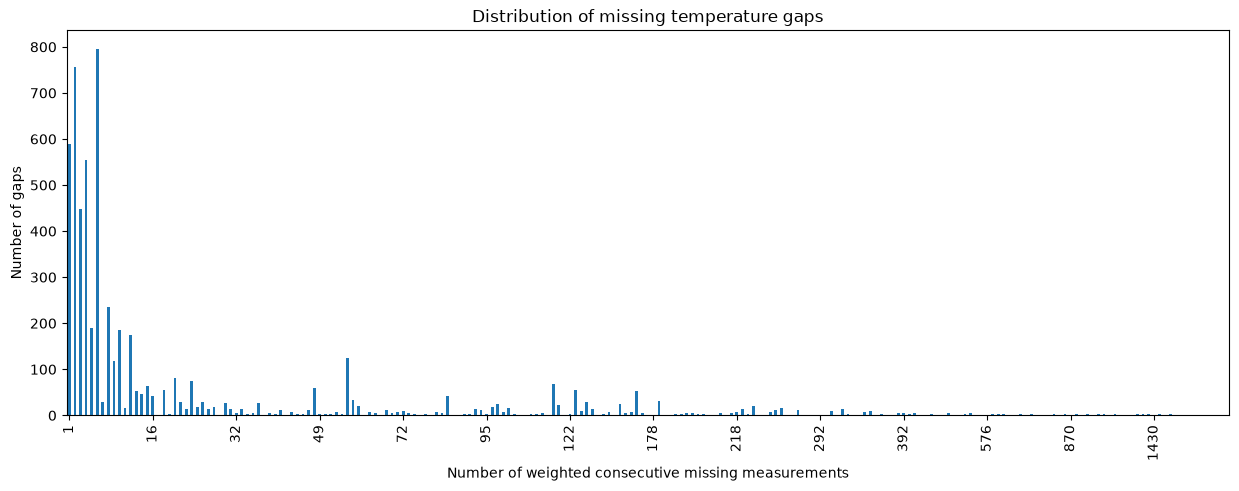

In [8]:
df_missing = df_city_cleaned.sort_values(
    ["lat_numeric", "long_numeric", "dt"]
).copy()

city_cols = ["lat_numeric", "long_numeric"]

df_missing["is_missing"] = df_missing["AverageTemperatureCleaned"].isna()

df_missing["gap_id"] = (
    df_missing.groupby(city_cols)["is_missing"]
    .transform(lambda x: x.ne(x.shift()).cumsum())
)

df_gaps = (
    df_missing[df_missing["is_missing"]]
    .groupby(city_cols + ["gap_id"])
    .agg(
        City=("City", "first"),
        Country=("Country", "first"),
        StartDate=("dt", "min"),
        EndDate=("dt", "max"),
        GapLength=("dt", "size")
    )
    .reset_index()
)

gap_counts = df_gaps["GapLength"].value_counts().sort_index()
gap_counts.plot(kind="bar", figsize=(15, 5))

plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=15, integer=True))
plt.xlabel("Number of weighted consecutive missing measurements")
plt.ylabel("Number of gaps")
plt.xticks()
plt.title("Distribution of missing temperature gaps")

plt.show()

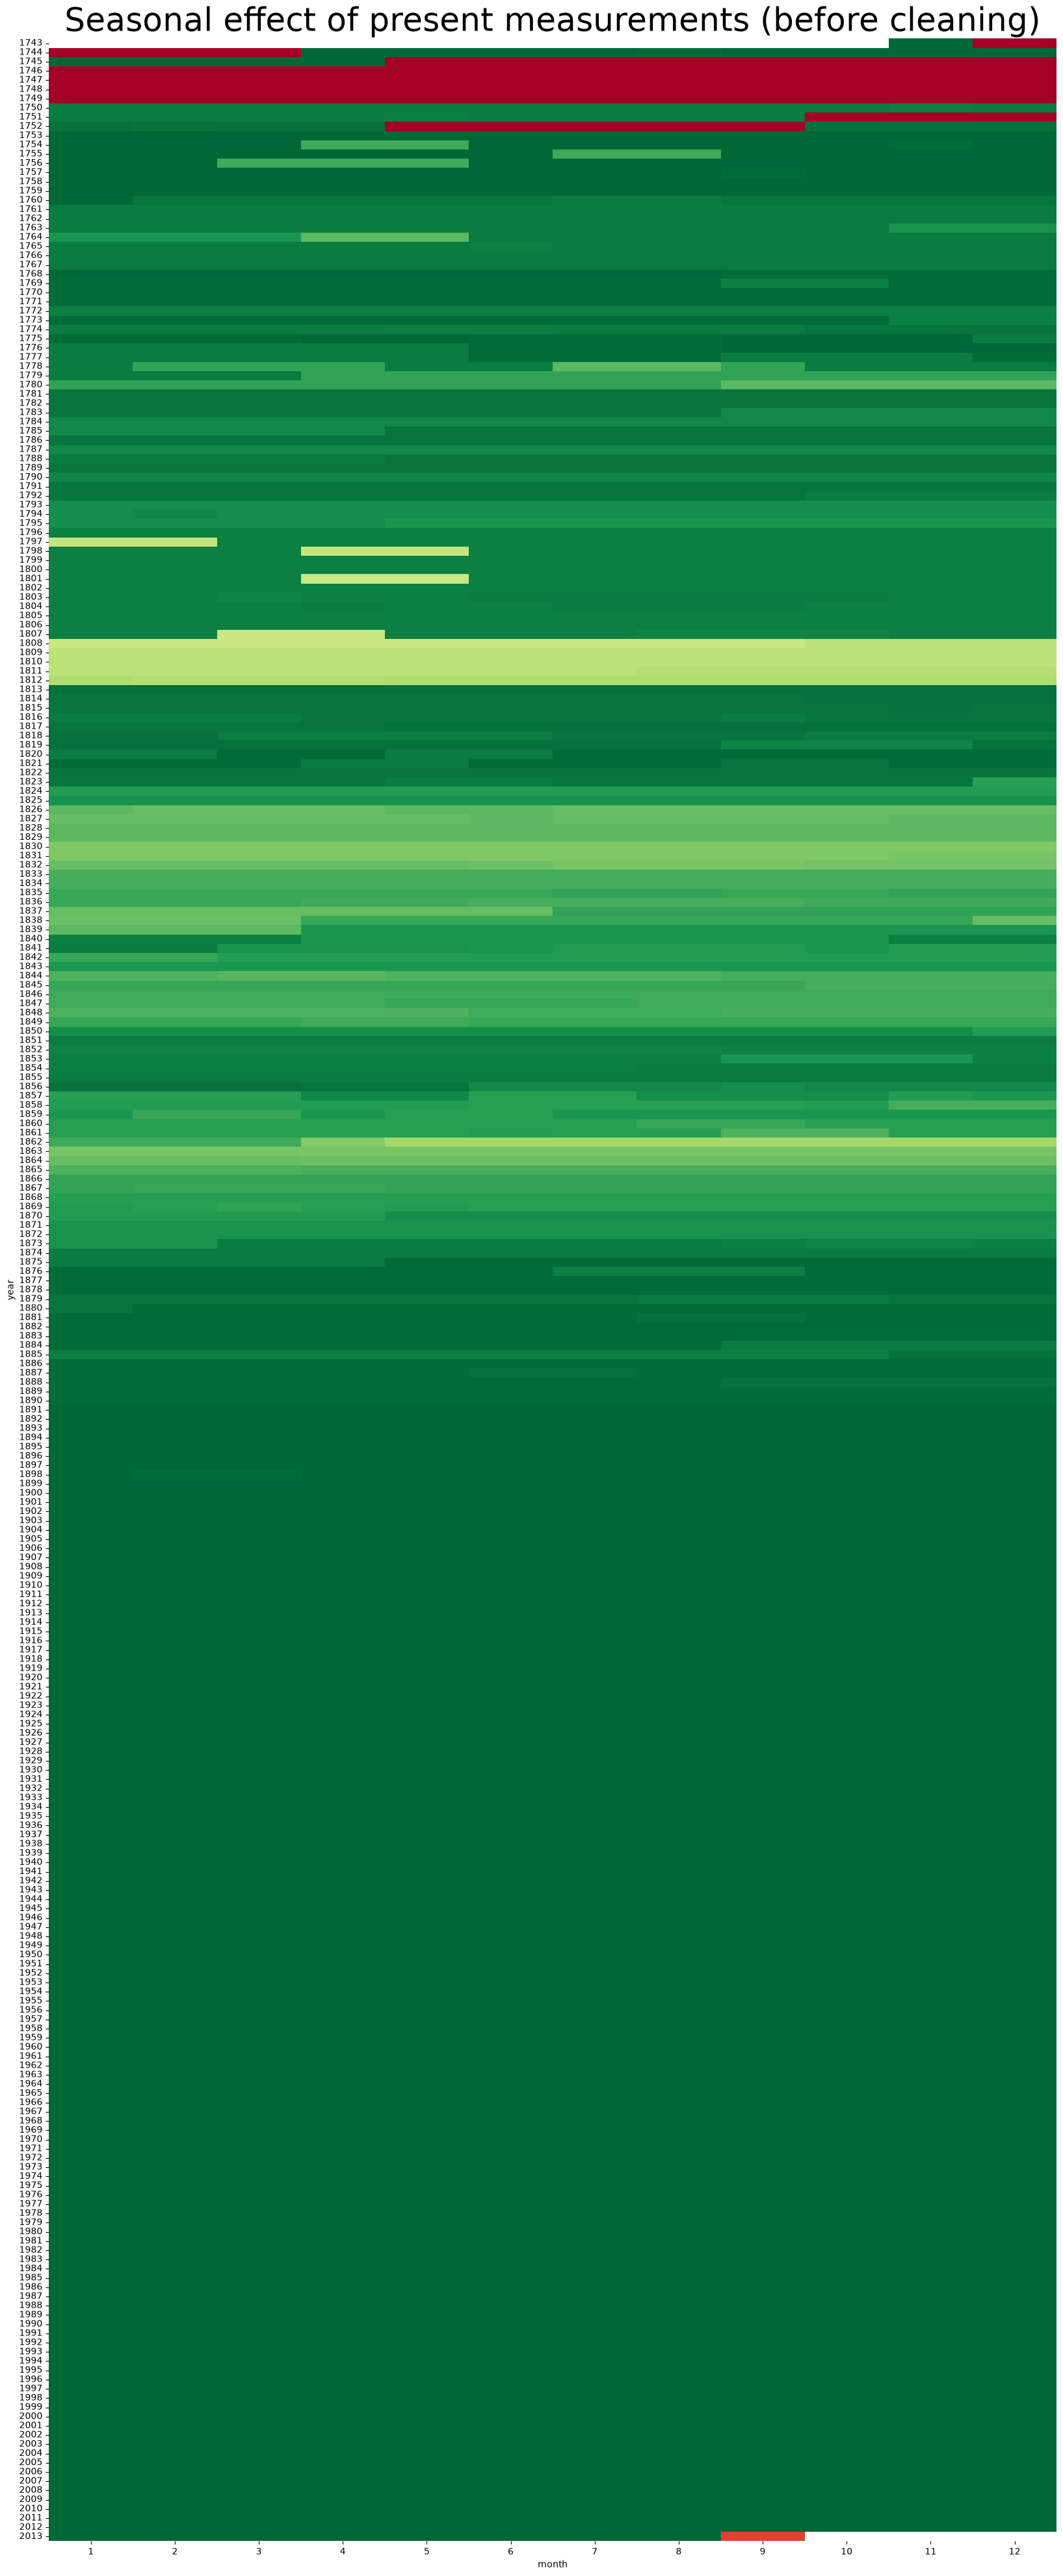

In [23]:
df_missing_per_date = df_city_cleaned.groupby(["dt"], as_index=False)["AverageTemperature"].agg(nr_of_measurements="count", nr_of_dates="size")
df_missing_per_date["proportion_present"] = round((df_missing_per_date["nr_of_measurements"] / df_missing_per_date["nr_of_dates"]), 2)
df_missing_per_date["year"] = df_missing_per_date.dt.dt.year
df_missing_per_date["month"] = df_missing_per_date.dt.dt.month

heatmap_data = df_missing_per_date.pivot(columns="month", index="year", values="proportion_present")

plt.figure(figsize=(20, 50))
sns.heatmap(
    heatmap_data,
    fmt=".2f",
    cmap="RdYlGn",
    cbar=False
    # linewidths=0.5,
)

plt.title("Seasonal effect of present measurements (before cleaning)", fontsize=36)
plt.show()

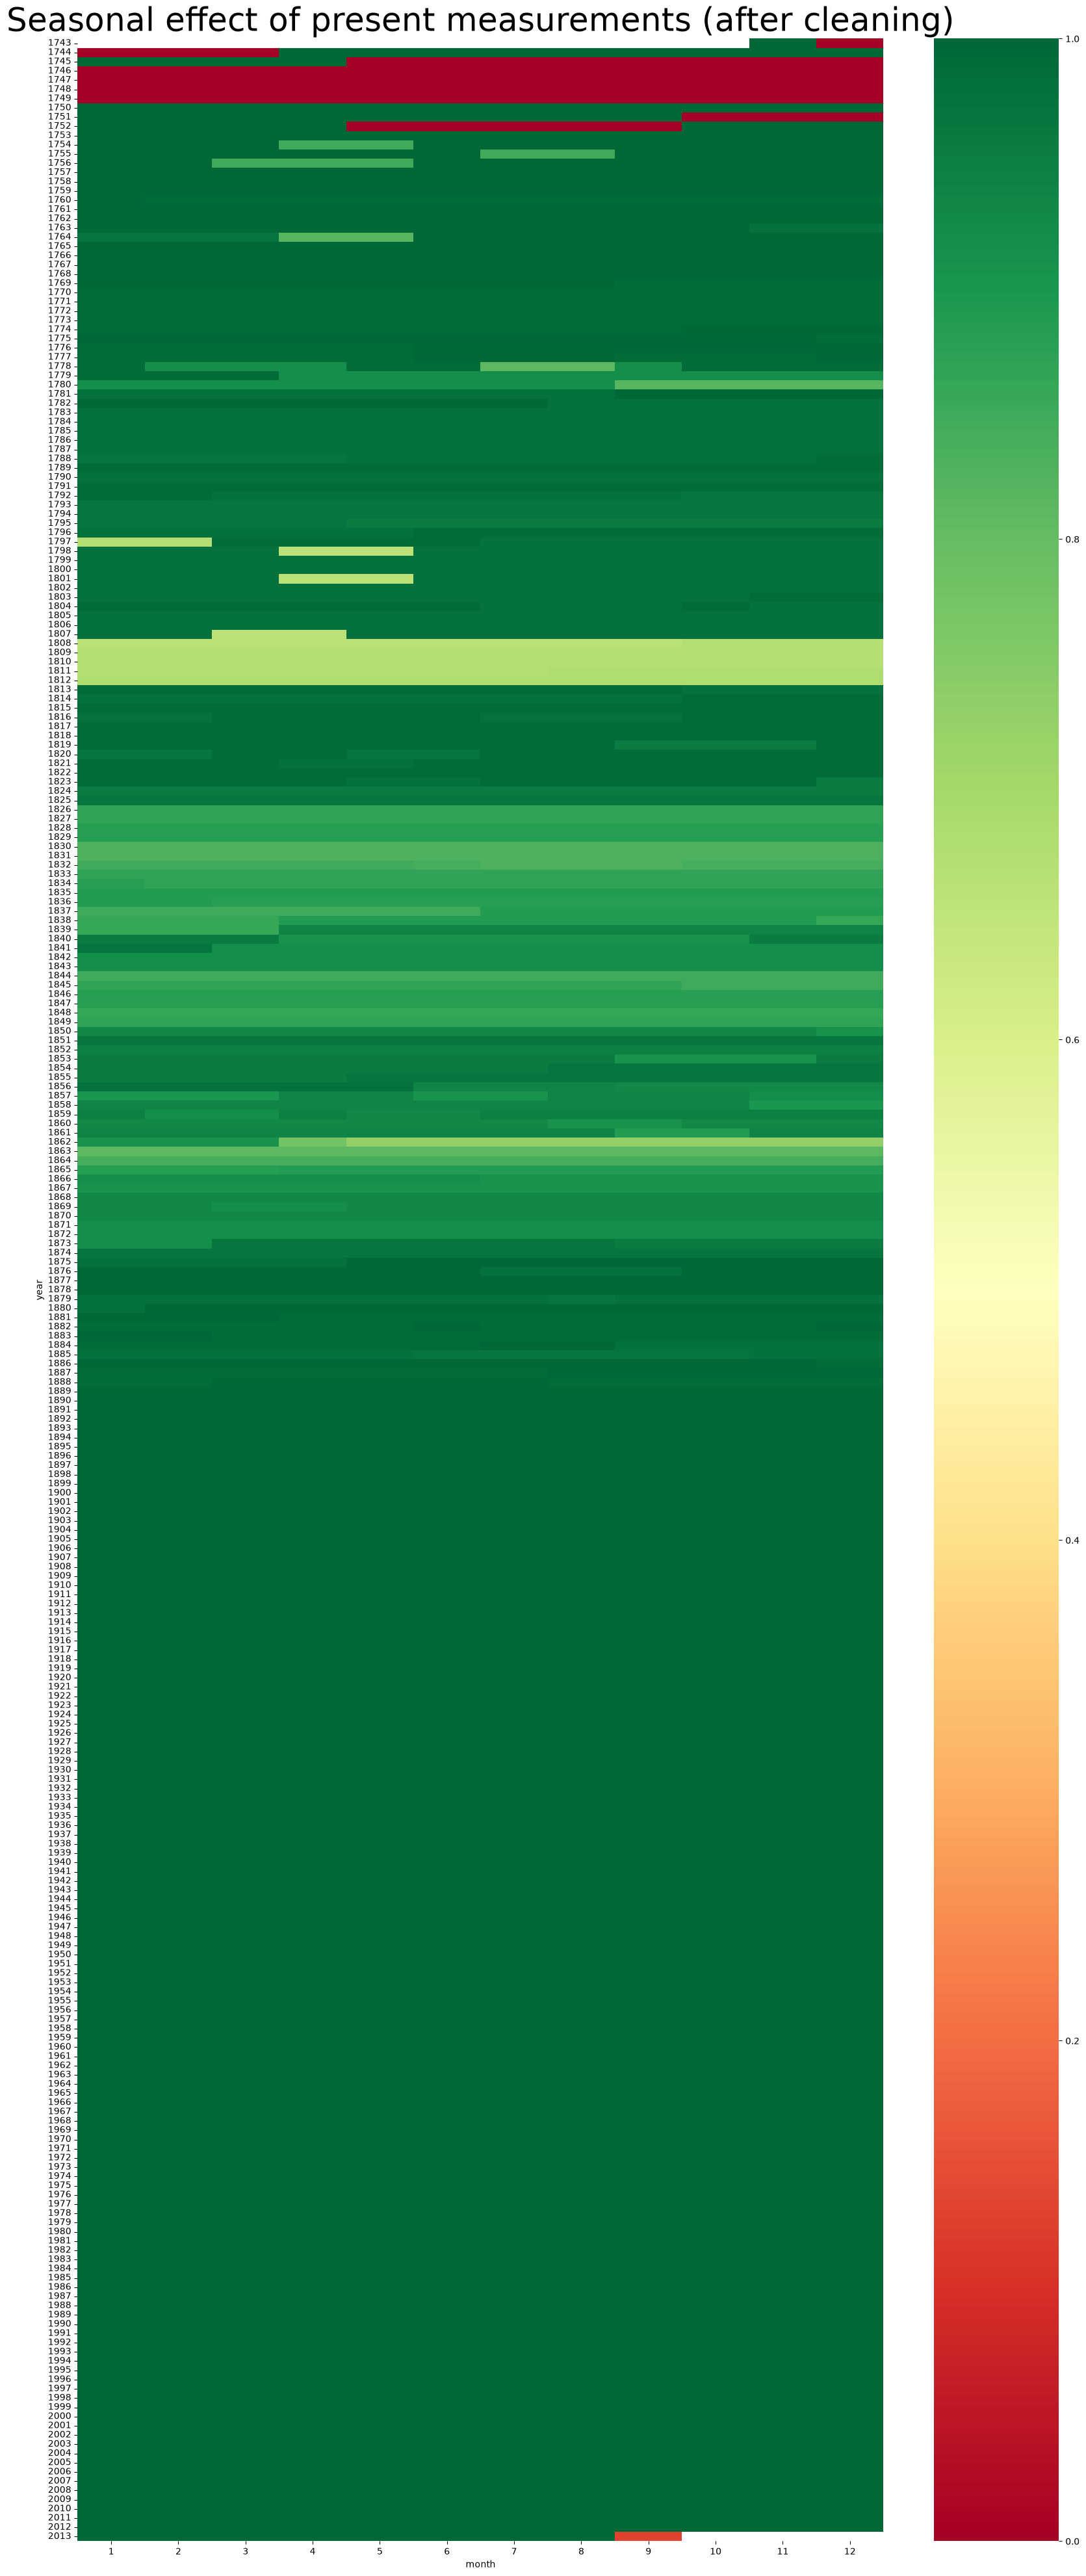

In [47]:
df_missing_per_date = df_city_cleaned.groupby(["dt"], as_index=False)["AverageTemperatureCleaned"].agg(nr_of_measurements="count", nr_of_dates="size")
df_missing_per_date["proportion_present"] = round((df_missing_per_date["nr_of_measurements"] / df_missing_per_date["nr_of_dates"]), 2)
df_missing_per_date["year"] = df_missing_per_date.dt.dt.year
df_missing_per_date["month"] = df_missing_per_date.dt.dt.month

heatmap_data = df_missing_per_date.pivot(columns="month", index="year", values="proportion_present")

plt.figure(figsize=(20, 50))
sns.heatmap(
    heatmap_data,
    fmt=".2f",
    cmap="RdYlGn",
    # linewidths=0.5,
)

plt.title("Seasonal effect of present measurements (after cleaning)", fontsize=36)
plt.show()

In [31]:
df_missing_per_location = df_city_cleaned.groupby(["lat_numeric", "long_numeric"], as_index=False)["AverageTemperatureCleaned"].agg(nr_of_measurements="count", nr_of_locations="size")
df_missing_per_location["proportion_present"] = round(((df_missing_per_location["nr_of_measurements"] / df_missing_per_location["nr_of_locations"])) * 100, 2)

fig = px.scatter_geo(
    data_frame=df_missing_per_location,
    lat=df_missing_per_location["lat_numeric"],
    lon=df_missing_per_location["long_numeric"],
    color="proportion_present",
    color_continuous_scale="RdYlGn",
    title="Percentage Present Measurements per City",
    )
fig.show()

# Save cleaned datasets

In [37]:
# Save new results
df_city_cleaned.to_parquet("ClimateData_clean/city_data.parquet")
df_major_city_cleaned.to_parquet("ClimateData_clean/major_city_data.parquet")
df_global_sorted.to_parquet("ClimateData_clean/global_data.parquet")